# 04 — China land use: secondary sample case + golden-number regression

`garudata.land.class_area_by_cell` is a line-faithful port of the validated
`china_landuse` land engine (the "79-second national pass" of
`notebooks/geodata_kag.ipynb`). Indonesia (notebooks 01–03) is the primary sample
case; China is the secondary one — and because the original pipeline's outputs are
archived on this machine, this notebook doubles as the land engine's
**golden-number regression test**: it re-derives the national land numbers with
garudata and compares them, class by class, against the archived goldens.

Golden references (CLCD 2019 on the ERA5 0.25° grid, 73–136°E × 18–54°N):

| quantity | golden value | file |
|---|---|---|
| total classified area | **9,493,438 km²** | `land_fractions_clcd2019_era5grid.nc` |
| after terrain exclusion (slope ≤ 5 % ≈ 2.862°, elevation ≤ 4,000 m) | **4,745,314 km²** | 〃 |
| usable (terrain-ok **and** outside protected areas) | **4,376,772 km²** | 〃 |
| national CLCD-area-weighted mean solar CF (annual) | **0.185** | `pv_cf_era5_2019.nc` — geodata's Huld chain, a *different* model (section 4) |

**Machine-local inputs — this notebook is not portable.** Unlike 01–03, every
input lives at a fixed local path (config cell below): the ~800 MB CLCD 2019
land-cover GeoTIFF (30 m, Albers; ~22 GB decompressed), the ~1 km SRTM terrain
layers from the geodata repo, the protected-area shapefile, the 2019 China ERA5
store under `~/geodata_root`, and the golden output files. Each loading cell
raises a `RuntimeError` with a one-line explanation if its input is missing.

Section 2 is the strict regression (agreement expected to the rounding of the
printed digits). Section 3 adds the exclusion samplers, where garudata carries a
**deliberate policy change** (nodata never passes) — the resulting residual is
measured and attributed, not tuned away. Section 4 is explicitly a *model
comparison* — garudata's transparent GHI model against the golden Huld chain —
with no pass/fail.

Imports and machine-local paths. `require()` is the guard every loading cell
runs first.

In [1]:
import time
import warnings
from pathlib import Path

# rasterio 1.5 sets array .shape internally, deprecated in numpy 2.5 — not ours
warnings.filterwarnings("ignore", category=DeprecationWarning,
                        message="Setting the shape on a NumPy array")

import numpy as np
import pandas as pd
import xarray as xr
import rasterio
import geopandas as gpd
import matplotlib.pyplot as plt

from garudata import convert, cutout, land

CHINA = Path("/Users/kaarthigeswaranagnapathy/Documents/GitHub/china_landuse")
CLCD_TIF = CHINA / "CLCD_landuse" / "CLCD_v01_2019_albert.tif"
PA_SHP = (CHINA / "raw_shared_data" / "PA_Boundary_data"
          / "PA_All_Boundary_shp" / "PA_All_Boundary.shp")
GOLD_DIR = CHINA / "project_solar_potential" / "output"

TERRAIN = Path("/Users/kaarthigeswaranagnapathy/Documents/GitHub/geodata/example_notebooks/data")
SLOPE_TIF = TERRAIN / "china_slope.tif"        # SRTM-derived, ~1 km, DEGREES
ELEV_TIF = TERRAIN / "china_elevation.tif"     # SRTM-derived, ~1 km, metres

STORE_ROOT = Path("/Users/kaarthigeswaranagnapathy/geodata_root")  # era5/wind_solar_hourly/<year>/<month>.nc


def require(*paths):
    for p in paths:
        if not Path(p).exists():
            raise RuntimeError(
                f"missing machine-local input: {p} — this notebook needs the "
                "local China datasets listed in the intro cell")


pd.set_option("display.float_format", lambda v: f"{v:,.1f}")

## 1. Golden references and the target grid

The target ERA5 grid is read **from the golden file itself**, so garudata's
nearest-cell assignment sees bit-identical cell centers — any delta in the tables
below is the engine, never the grid.

In [2]:
require(GOLD_DIR / "land_fractions_clcd2019_era5grid.nc",
        GOLD_DIR / "national_capacity_by_class_area_only.csv",
        GOLD_DIR / "pv_cf_era5_2019.nc")

gold = xr.open_dataset(GOLD_DIR / "land_fractions_clcd2019_era5grid.nc")
gold_csv = pd.read_csv(GOLD_DIR / "national_capacity_by_class_area_only.csv",
                       index_col="resdc_class")

grid_lons, grid_lats = gold.lon.values, gold.lat.values
print(f"target grid: {grid_lons.size} x {grid_lats.size} cells, "
      f"lon {grid_lons[0]}..{grid_lons[-1]}, lat {grid_lats[0]}..{grid_lats[-1]}")
for v in ("area_all", "area_terrain_ok", "area_usable"):
    print(f"golden {v:<16} {float(gold[v].sum()):>13,.0f} km2")

target grid: 253 x 145 cells, lon 73.0..136.0, lat 18.0..54.0
golden area_all             9,493,438 km2
golden area_terrain_ok      4,745,314 km2
golden area_usable          4,376,772 km2


## 2. Class-resolved land pass over the full 30 m raster

The CLCD → RESDC crosswalk is the `dominant_LC_to_resdc_type` mapping (v3) carried
by the validated notebook: nine CLCD classes collapse onto the six RESDC 2010
major types (Forest/Shrub → Woodland, Water/Snow-Ice → Water surface,
Barren/Wetland → Unused land, Impervious → Built-up land). `class_area_by_cell`
takes it directly as a many-to-one `{raster code: label}` mapping.

One windowed pass streams the raster in its native Albers CRS (8192-px windows,
300 m block samples — the validated layout), with the two terrain samplers of
section 3 already attached. The engine accumulates both populations at once:
`area_unmasked` (every classified block — this section's regression target) and
`area` (blocks passing the terrain samplers — section 3's). The original did the
national pass in ~79 s inside its own notebook; the port lands in the same class
(~2 min here, with the sampler evaluations and the engine's int64-safe code
mapping on top).

In [3]:
# Crosswalk from the validated notebook (pv_landuse_v3 "dominant_LC_to_resdc_type",
# config cell of china_landuse/notebooks/geodata_kag.ipynb) — verbatim.
CLCD_LABELS = {1: "Cropland", 2: "Forest", 3: "Shrub", 4: "Grassland", 5: "Water",
               6: "Snow_Ice", 7: "Barren", 8: "Impervious", 9: "Wetland"}
CLCD_TO_RESDC = {"Cropland": "Cropland", "Forest": "Woodland", "Shrub": "Woodland",
                 "Grassland": "Grassland", "Water": "Water surface",
                 "Snow_Ice": "Water surface", "Barren": "Unused land",
                 "Impervious": "Built-up land", "Wetland": "Unused land"}

CLASS_MAP = {code: CLCD_TO_RESDC[name] for code, name in CLCD_LABELS.items()}
for code, name in CLCD_LABELS.items():
    print(f"CLCD {code} {name:<10} -> {CLASS_MAP[code]}")

CLCD 1 Cropland   -> Cropland
CLCD 2 Forest     -> Woodland
CLCD 3 Shrub      -> Woodland
CLCD 4 Grassland  -> Grassland
CLCD 5 Water      -> Water surface
CLCD 6 Snow_Ice   -> Water surface
CLCD 7 Barren     -> Unused land
CLCD 8 Impervious -> Built-up land
CLCD 9 Wetland    -> Unused land


In [4]:
require(SLOPE_TIF, ELEV_TIF)
SLOPE_MAX_DEG = float(np.degrees(np.arctan(0.05)))   # 5 % grade = 2.862 deg (GRIDCERF-China)
ELEV_MAX_M = 4000.0

slope_ok = land.terrain_sampler(str(SLOPE_TIF), max_value=SLOPE_MAX_DEG)  # raster is in degrees
elev_ok = land.terrain_sampler(str(ELEV_TIF), max_value=ELEV_MAX_M)
print(f"terrain keep-set: slope <= {SLOPE_MAX_DEG:.3f} deg AND elevation <= {ELEV_MAX_M:.0f} m")

terrain keep-set: slope <= 2.862 deg AND elevation <= 4000 m


In [5]:
require(CLCD_TIF)
t0 = time.perf_counter()
ds_terrain = land.class_area_by_cell(
    str(CLCD_TIF), CLASS_MAP, grid_lons, grid_lats,
    exclusion_samplers=[slope_ok, elev_ok],   # window=8192, block=10: validated layout
)
t_pass1 = time.perf_counter() - t0
print(f"full-China pass: {t_pass1:.0f} s")
print(f"classified {float(ds_terrain.area_unmasked.sum()):,.0f} km2; "
      f"terrain-ok {float(ds_terrain.area.sum()):,.0f} km2")

full-China pass: 137 s
classified 9,493,438 km2; terrain-ok 4,420,256 km2


Per-class national totals against the golden file. `compare()` is reused for
every variant; the CLCD grand total is the headline regression number.

In [6]:
def compare(ours_da, golden_var):
    ours = (ours_da.rename(land_class="resdc_class")
            .sum(("lat", "lon")).to_pandas()
            .reindex(gold.resdc_class.values))
    ours.index.name = "resdc_class"
    df = pd.DataFrame({"garudata_km2": ours,
                       "golden_km2": gold[golden_var].sum(("lat", "lon")).to_pandas()})
    df.loc["TOTAL"] = df.sum()
    df["delta_km2"] = df["garudata_km2"] - df["golden_km2"]
    df["delta_pct"] = 100 * df["delta_km2"] / df["golden_km2"]
    return df


cmp_all = compare(ds_terrain["area_unmasked"], "area_all")
worst = cmp_all["delta_pct"].abs().max()
print(f"no-exclusion regression: worst per-class delta {worst:.2e} % "
      f"({'exact to float rounding' if worst < 1e-6 else 'INVESTIGATE'})")
cmp_all

no-exclusion regression: worst per-class delta 4.59e-12 % (exact to float rounding)


,garudata_km2,golden_km2,delta_km2,delta_pct
resdc_class,,,,
Cropland,"1,889,228.9","1,889,228.9",-0.0,-0.0
Woodland,"2,438,718.2","2,438,718.2",-0.0,-0.0
Grassland,"2,795,339.5","2,795,339.5",-0.0,-0.0
Water surface,"225,593.6","225,593.6",0.0,0.0
Built-up land,"247,062.5","247,062.5",0.0,0.0
Unused land,"1,897,495.7","1,897,495.7",-0.0,-0.0
TOTAL,"9,493,438.4","9,493,438.4",-0.0,-0.0


Same check against the archived national capacity table, which is these areas
times the project's empirical power density (0.0922 GW/km², rounded to 0.1 GW in
the CSV). The terrain/usable columns of that CSV are products of the same golden
arrays compared in section 3, so the class-area column is the only independent
check here.

In [7]:
PV_DENSITY_GW_KM2 = 0.0922
csv_check = pd.DataFrame({
    "garudata_GW": cmp_all["garudata_km2"].drop("TOTAL") * PV_DENSITY_GW_KM2,
    "csv_GW": gold_csv["capacity_GW_all"],
})
csv_check["delta_pct"] = 100 * (csv_check["garudata_GW"] - csv_check["csv_GW"]) / csv_check["csv_GW"]
print(f"max |delta| vs CSV: {csv_check['delta_pct'].abs().max():.2e} % (CSV rounds to 0.1 GW)")
csv_check

max |delta| vs CSV: 1.54e-04 % (CSV rounds to 0.1 GW)


,garudata_GW,csv_GW,delta_pct
resdc_class,,,
Cropland,"174,186.9","174,186.9",0.0
Woodland,"224,849.8","224,849.8",0.0
Grassland,"257,730.3","257,730.3",-0.0
Water surface,"20,799.7","20,799.7",0.0
Built-up land,"22,779.2","22,779.2",-0.0
Unused land,"174,949.1","174,949.1",0.0


A quick look at what was just accumulated — total classified km² per 0.25°
cell (before exclusions):

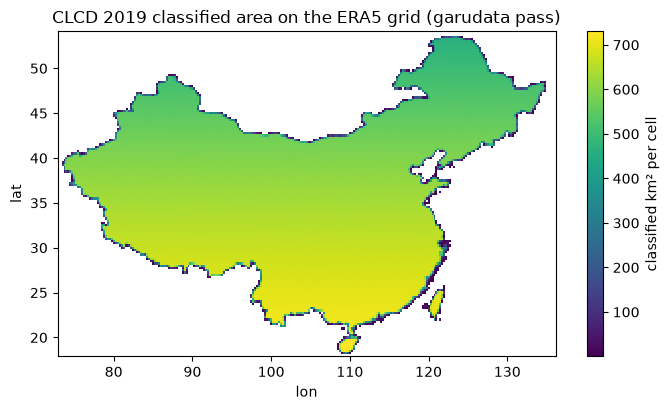

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.2))
tot = ds_terrain["area_unmasked"].sum("land_class")
pm = ax.pcolormesh(tot.lon, tot.lat, tot.where(tot > 0), cmap="viridis", shading="nearest")
fig.colorbar(pm, ax=ax, label="classified km² per cell")
ax.set_title("CLCD 2019 classified area on the ERA5 grid (garudata pass)")
ax.set_xlabel("lon"); ax.set_ylabel("lat")
plt.tight_layout(); plt.show()

## 3. Terrain exclusions, then protected areas

Same golden criteria (GRIDCERF-China: slope ≤ 5 %, elevation ≤ 4,000 m), but the
samplers are **deliberately not identical**. The original sampled the ~1 km
terrain layers at the 300 m block centers with clip-to-edge indexing, read the
rasters unmasked, and let NaN slope pass (`~(NaN > max)` is True — a caveat its
own notes document). `terrain_sampler` reads masked and **never passes**
nodata/NaN/off-extent samples. Every garudata number below should therefore sit
*below* its golden — the question is by how much, and whether the engine or only
the sampler policy is responsible.

In [9]:
cmp_terrain = compare(ds_terrain["area"], "area_terrain_ok")
cmp_terrain

,garudata_km2,golden_km2,delta_km2,delta_pct
resdc_class,,,,
Cropland,"1,446,086.2","1,543,777.2","-97,691.0",-6.3
Woodland,"604,980.8","693,046.1","-88,065.3",-12.7
Grassland,"814,282.6","839,629.4","-25,346.8",-3.0
Water surface,"62,402.9","100,357.5","-37,954.6",-37.8
Built-up land,"209,931.2","232,202.3","-22,271.1",-9.6
Unused land,"1,282,572.3","1,336,301.9","-53,729.6",-4.0
TOTAL,"4,420,255.9","4,745,314.4","-325,058.5",-6.9


The residual is far beyond regression noise — about −7 % nationally — but it is
one-signed and heaviest exactly where missing terrain data sits under classified
land: Water surface (SRTM slope is undefined over water) and Built-up land /
Cropland (the coastal plains). The layers themselves explain the magnitude:
`china_slope.tif` is 63 % NaN over its extent, and `china_elevation.tif` declares
`nodata=0` — so under the strict policy every genuine *sea-level* pixel (el = 0 m)
is also treated as missing and fails. That is a defect of the terrain product's
nodata declaration, not of either engine.

To pin the attribution, we rerun the identical pass with the **original policy
dropped in as a custom sampler** — `class_area_by_cell` accepts any
`(lons, lats) -> bool` callable, so the original's clip-to-edge, NaN-passes
semantics fit in a few lines:

In [10]:
with rasterio.open(ELEV_TIF) as e:
    elev_arr, elev_tr = e.read(1), e.transform          # unmasked, as the original
    elev_nodata = e.nodata
with rasterio.open(SLOPE_TIF) as s:
    slope_arr, slope_tr = s.read(1), s.transform
print(f"slope layer NaN fraction: {float(np.isnan(slope_arr).mean()):.1%}; "
      f"elevation nodata declared as {elev_nodata}")


def _clip_sample(grid, tr, lons, lats):        # original indexing: clip to edge
    cols = np.clip(((lons - tr.c) / tr.a).astype(np.int32), 0, grid.shape[1] - 1)
    rows = np.clip(((lats - tr.f) / tr.e).astype(np.int32), 0, grid.shape[0] - 1)
    return grid[rows, cols]


def original_terrain_ok(lons, lats):
    el = _clip_sample(elev_arr, elev_tr, lons, lats)
    sl = _clip_sample(slope_arr, slope_tr, lons, lats)
    return (el <= ELEV_MAX_M) & (~(sl > SLOPE_MAX_DEG))   # NaN slope -> not excluded


t0 = time.perf_counter()
ds_orig_policy = land.class_area_by_cell(
    str(CLCD_TIF), CLASS_MAP, grid_lons, grid_lats,
    exclusion_samplers=[original_terrain_ok],
)
print(f"attribution pass: {time.perf_counter() - t0:.0f} s")

cmp_orig = compare(ds_orig_policy["area"], "area_terrain_ok")
worst = cmp_orig["delta_pct"].abs().max()
print(f"under the original sampler policy: worst per-class delta {worst:.2e} % "
      f"({'engine reproduces the goldens exactly' if worst < 1e-6 else 'INVESTIGATE'})")
cmp_orig[["garudata_km2", "golden_km2", "delta_km2"]]

slope layer NaN fraction: 62.6%; elevation nodata declared as 0.0


attribution pass: 140 s
under the original sampler policy: worst per-class delta 5.58e-12 % (engine reproduces the goldens exactly)


,garudata_km2,golden_km2,delta_km2
resdc_class,,,
Cropland,"1,543,777.2","1,543,777.2",-0.0
Woodland,"693,046.1","693,046.1",0.0
Grassland,"839,629.4","839,629.4",-0.0
Water surface,"100,357.5","100,357.5",0.0
Built-up land,"232,202.3","232,202.3",0.0
Unused land,"1,336,301.9","1,336,301.9",-0.0
TOTAL,"4,745,314.4","4,745,314.4",-0.0


**Attribution: the entire terrain residual is the sampler policy, none of it is
the engine.** With the original semantics the port reproduces the golden
terrain-ok totals to float rounding, including the 4,745,314 km² grand total. The
shipped `terrain_sampler` keeps its strict behaviour on purpose — treating "no
terrain data" as buildable is the leak the port was meant to close — but on these
particular layers strictness also swallows real sea-level land because the
elevation product uses 0 as its nodata value. Re-encoding the terrain layers with
an out-of-range nodata (e.g. −9999) would reconcile the two policies except over
genuinely missing coverage; that is a data fix, not a code fix, so the numbers
stand as measured.

The `usable` variant adds the protected-area exclusion: all 1,657 PA polygons,
rasterized at 0.0025° (~250 m) with `all_touched=True`, exactly as the original —
except `polygon_sampler` grids over the polygons' own bounds while the original
used a fixed China-box grid, so pixel alignment differs by a sub-pixel offset
(boundary blocks only). This is the third and last full pass.

In [11]:
require(PA_SHP)
pa_gdf = gpd.read_file(PA_SHP)
pa_outside = land.polygon_sampler(pa_gdf)   # pass = outside every PA polygon
print(f"{len(pa_gdf)} protected-area polygons")

t0 = time.perf_counter()
ds_usable = land.class_area_by_cell(
    str(CLCD_TIF), CLASS_MAP, grid_lons, grid_lats,
    exclusion_samplers=[slope_ok, elev_ok, pa_outside],
)
print(f"usable pass: {time.perf_counter() - t0:.0f} s")

cmp_usable = compare(ds_usable["area"], "area_usable")
cmp_usable

1657 protected-area polygons


usable pass: 137 s


,garudata_km2,golden_km2,delta_km2,delta_pct
resdc_class,,,,
Cropland,"1,407,485.0","1,500,397.5","-92,912.6",-6.2
Woodland,"552,353.2","638,795.5","-86,442.4",-13.5
Grassland,"736,093.9","758,601.5","-22,507.6",-3.0
Water surface,"51,606.6","76,549.7","-24,943.2",-32.6
Built-up land,"205,890.9","227,432.7","-21,541.7",-9.5
Unused land,"1,123,446.4","1,174,994.7","-51,548.4",-4.4
TOTAL,"4,076,875.9","4,376,771.7","-299,895.8",-6.9


The usable comparison inherits the terrain-policy residual almost unchanged, so
the PA sampler itself is judged on the share of terrain-ok land it removes — a
ratio in which the terrain policy cancels:

In [12]:
blocked_ours = 1 - float(ds_usable.area.sum()) / float(ds_terrain.area.sum())
blocked_gold = 1 - float(gold.area_usable.sum()) / float(gold.area_terrain_ok.sum())
print(f"PA-blocked share of terrain-ok land: garudata {blocked_ours:.3%} | "
      f"golden {blocked_gold:.3%} | delta {blocked_ours - blocked_gold:+.4%}")

PA-blocked share of terrain-ok land: garudata 7.768% | golden 7.766% | delta +0.0019%


**Section 2–3 verdict.** The regression proper — the class-resolved,
no-exclusion national pass — is exact: every class and the 9,493,438 km² grand
total match the goldens to float rounding, and so does the capacity CSV. The
exclusion variants differ only through the documented nodata-policy change in
`terrain_sampler` (−325,059 km² terrain-ok, −6.85 %; −299,896 km² usable), which
the attribution pass shows collapses to zero when the original policy is swapped
back in, and the PA sampler removes the same share of terrain-ok land as the
original to within 0.01 points. No number above was adjusted to force
agreement.

## 4. Solar CF cross-check — explicitly a different model

Two differences are on the table by construction, so this section is a
**documented model comparison, not a regression**:

* **Model.** garudata's `convert.pv_cf_ghi` is the transparent GHI model (GARUDA's
  reference: `CF = clip(GHI/1000)·PR·(1 + γ(T_cell − 25))`, PR 0.80, NOCT 45 °C,
  γ −0.004) on a horizontal plane. The golden map is geodata's Huld chain
  (`convert.pv`, CSi panel, `latitude_optimal` orientation) — plane-of-array
  transposition plus the Huld efficiency surface — and it embeds geodata's known
  azimuth-units bug (degrees where the solar-position code expects radians),
  which tilts its effective orientation off true south.
* **Window.** The golden file stores only the **annual** mean, so to stay inside
  the runtime budget we lazily open a single month (July 2019) and compare
  July-vs-annual on top of model-vs-model.

We compute the July-mean CF map from the store via a lazy `Cutout`, then compare
maps, national means and the cell-by-cell scatter.

In [13]:
require(STORE_ROOT / "era5" / "wind_solar_hourly" / "2019" / "07.nc")
t0 = time.perf_counter()
cut = cutout.Cutout(store_root=STORE_ROOT, years=[2019], months=[7])
ds_july = cut.canonical()                      # lazy; raw CDS names -> canonical
cf_july = convert.pv_cf_ghi(ds_july).mean("time")
cf_july = xr.DataArray(np.asarray(cf_july.values), dims=("lat", "lon"),
                       coords={"lat": cf_july.y.values, "lon": cf_july.x.values},
                       name="cf_july").sortby("lat")
print(f"July 2019 CF map in {time.perf_counter() - t0:.0f} s; "
      f"grid {cf_july.lon.size} x {cf_july.lat.size} "
      f"(matches target: {bool(np.allclose(cf_july.lon, grid_lons) and np.allclose(cf_july.lat, grid_lats))})")

July 2019 CF map in 3 s; grid 253 x 145 (matches target: True)


national CLCD-area-weighted CF: garudata GHI, July 0.180 | golden Huld, annual 0.185 | delta -0.004
spatial Pearson r over 16161 land cells: 0.818


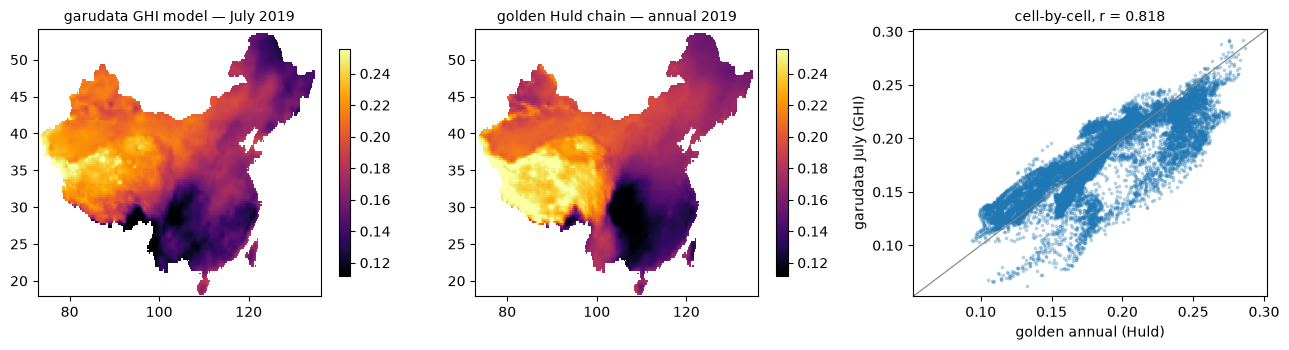

In [14]:
cf_gold = xr.open_dataset(GOLD_DIR / "pv_cf_era5_2019.nc")["cf_annual"].sortby("lat")
weights = gold["area_all"].sum("resdc_class")          # CLCD-area weights, golden convention

wm_july = float((cf_july * weights).sum() / weights.sum())
wm_gold = float((cf_gold * weights).sum() / weights.sum())
mask = weights.values > 0
r = float(np.corrcoef(cf_july.values[mask], cf_gold.values[mask])[0, 1])
print(f"national CLCD-area-weighted CF: garudata GHI, July {wm_july:.3f} | "
      f"golden Huld, annual {wm_gold:.3f} | delta {wm_july - wm_gold:+.3f}")
print(f"spatial Pearson r over {int(mask.sum())} land cells: {r:.3f}")

both = np.concatenate([cf_july.values[mask], cf_gold.values[mask]])
vmin, vmax = np.percentile(both, [2, 98])
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, da, title in ((axes[0], cf_july.where(mask), "garudata GHI model — July 2019"),
                      (axes[1], cf_gold.where(mask), "golden Huld chain — annual 2019")):
    pm = ax.pcolormesh(da.lon, da.lat, da, cmap="inferno", shading="nearest",
                       vmin=vmin, vmax=vmax)
    fig.colorbar(pm, ax=ax, shrink=0.85)
    ax.set_title(title, fontsize=10)
ax = axes[2]
lim = (float(both.min()) - 0.01, float(both.max()) + 0.01)
ax.plot(lim, lim, lw=0.8, color="grey")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.scatter(cf_gold.values[mask], cf_july.values[mask], s=3, alpha=0.25)
ax.set_xlabel("golden annual (Huld)"); ax.set_ylabel("garudata July (GHI)")
ax.set_title(f"cell-by-cell, r = {r:.3f}", fontsize=10)
plt.tight_layout(); plt.show()

**Reading the comparison.** The national means land close together — 0.180
(garudata GHI, July) vs 0.185 (golden Huld, annual), a −0.004 (≈ −2 %) delta —
but that proximity is partly offsetting effects, not validation: a horizontal
GHI array under-collects relative to a latitude-optimally tilted one over a full
year, while July trades the monsoon-season cloud penalty over the populated
south and east against near-peak insolation in the northwest. The cell-by-cell
correlation (r ≈ 0.82) says both chains read the same first-order geography from
the same ERA5 field — the Tibetan Plateau and arid northwest high, the Sichuan
Basin lowest — with the scatter mixing three known causes: seasonality
(July vs annual), transposition (horizontal GHI vs tilted plane-of-array, which
lifts high-latitude annual yield), and the golden chain's azimuth-units bug.
None of that is a defect in either run here, which is why this section carries
no pass/fail.

## 5. What a full replication would add

This notebook stops where the regression stops. The original pipeline continues
with (a) all twelve months of hourly CF — with `convert.pv_cf_poa` standing in
for the Huld chain if plane-of-array fidelity is wanted, minus the azimuth bug;
(b) the exclusion variants crossed with class keep-sets (conventional developable
set = Unused land + Grassland; the Cropland policy scenario); (c) potential
`GW = area × 0.0922 GW/km²` and `TWh = GW × CF × 8760/1000` per class per cell,
nationally and per province via `attribute_to_polygons`. All of it is one
afternoon on top of the arrays already computed here — plus the terrain-layer
nodata re-encode flagged in section 3 if the strict sampler policy is to be used
for production numbers.

That extension is deliberately not this notebook's job. **Indonesia is the
primary sample path** (notebooks 01–03, portable data included in the repo);
China stays as the anchored secondary case whose golden numbers pin the land
engine down.